# K-fold: direct vs recursive, all packs

Expanding-window time-series folds (not shuffled k-fold) for **hour**, **day**, and **week**.
Each fold trains once, then scores:

- **direct** — every row independently (what notebook 03 / 05 report)
- **recursive** — day/week only: demand lags roll from train-fold history, then that fold’s own P50. Weather stays on Previous Runs, not ERA5.

The hour pack is **direct only**. Live next-30 is one settlement period with real INDO `lag_1`. Walking `lag_1` across ~13k test half-hours is not how the pack is used and takes many hours (one LightGBM call per row).

Run on the **train** split only so the last eight weeks stay a true holdout. **Interrupt the current Fit-and-score cell** if it has been sitting on `k-fold hour rows 80543` with no further print, then re-run that cell (this file now prints each fold). Set `FAST = True` for a smoke run (2 folds, 80 trees).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "energy_forecast").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
HERE = ROOT / "notebooks" / "week" / "v1"
sys.path.insert(0, str(ROOT / "src"))

from energy_forecast.evaluate import kfold_all_packs, product_slices, time_series_kfold
from energy_forecast.features import FEATURE_COLUMNS, HOUR_FEATURE_COLUMNS
from energy_forecast.forecast import prepare_history
from energy_forecast.model import (
    DAY_MAX_LEAD_HOURS,
    EXCLUDE_TRAIN_YEARS,
    HOUR_EXCLUDE_TRAIN_YEARS,
    HOUR_MAX_LEAD_HOURS,
    LGB_WEEK,
    WEEK_N_ESTIMATORS,
    split_training_frame,
)
from energy_forecast.modes import MEDIUM, SHORT

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}" if pd.notna(v) else "")
print("repo", ROOT)

repo D:\energy-forecast


In [2]:
RUN_KFOLD = True
FAST = False  # True = 2 folds, 80 trees
N_SPLITS = 2 if FAST else 5
EMBARGO_DAYS = 0
TREES_HOUR = 80 if FAST else 400
TREES_DAY = 80 if FAST else 400
TREES_WEEK = 80 if FAST else WEEK_N_ESTIMATORS
print("splits", N_SPLITS, "fast", FAST, "week trees", TREES_WEEK)

splits 5 fast False week trees 450


## 1. Frames

Hour = ERA5 + short INDO lags. Day/week = Previous Runs leads 0–7. Same year filters as notebook 03. Last 56 days held out of k-fold.

In [3]:
week_hist = prepare_history()
hour_hist = prepare_history(weather_source="archive")
week_train, week_holdout = split_training_frame(
    week_hist, features=FEATURE_COLUMNS, exclude_years=EXCLUDE_TRAIN_YEARS
)
hour_train, hour_holdout = split_training_frame(
    hour_hist,
    features=HOUR_FEATURE_COLUMNS,
    exclude_years=HOUR_EXCLUDE_TRAIN_YEARS,
    max_lead_hours=HOUR_MAX_LEAD_HOURS,
)
print("week train", len(week_train), week_train["timestamp"].min(), "->", week_train["timestamp"].max())
print("hour train", len(hour_train), hour_train["timestamp"].min(), "->", hour_train["timestamp"].max())
print("holdout week", len(week_holdout), "hour", len(hour_holdout))

week train 363640 2024-01-01 00:00:00+00:00 -> 2026-08-05 00:00:00+01:00
hour train 80543 2022-01-01 00:00:00+00:00 -> 2026-08-06 00:00:00+01:00
holdout week 20744 hour 2689


## 2. Fit and score

One expanding fit per fold per pack. Recursive scoring is on that fold’s test window only.

In [4]:
def run_pack_kfold(pack, frame, **kwargs):
    print("k-fold", pack, "rows", len(frame))
    table, slices = time_series_kfold(
        frame,
        n_splits=N_SPLITS,
        embargo_days=EMBARGO_DAYS,
        pack=pack,
        return_slices=True,
        refit_full=False,
        **kwargs,
    )
    out = HERE / "kfold"
    out.mkdir(parents=True, exist_ok=True)
    table.to_parquet(out / f"{pack}_folds.parquet", index=False)
    slices.to_parquet(out / f"{pack}_slices.parquet", index=False)
    print(pack, "saved", out)
    return table, slices

hour_folds = day_folds = week_folds = None
hour_slices = day_slices = week_slices = None
if RUN_KFOLD:
    hour_folds, hour_slices = run_pack_kfold(
        "hour",
        hour_train,
        n_estimators=TREES_HOUR,
        features=HOUR_FEATURE_COLUMNS,
        max_lead_hours=HOUR_MAX_LEAD_HOURS,
        eval_mode=None,
        scoring=("direct",),
    )
    day_folds, day_slices = run_pack_kfold(
        "day",
        week_train,
        n_estimators=TREES_DAY,
        features=FEATURE_COLUMNS,
        max_lead_hours=DAY_MAX_LEAD_HOURS,
        eval_mode=SHORT,
    )
    week_folds, week_slices = run_pack_kfold(
        "week",
        week_train,
        n_estimators=TREES_WEEK,
        features=FEATURE_COLUMNS,
        mean_params=LGB_WEEK,
        residual_params=LGB_WEEK,
        eval_mode=MEDIUM,
        scoring=("direct", "recursive"),
    )
else:
    print("skipped — set RUN_KFOLD = True")

k-fold hour rows 80543
hour 1/5 train 13428 test 13423 fit…
hour 1/5 direct score…
hour 2/5 train 26851 test 13423 fit…
hour 2/5 direct score…
hour 3/5 train 40274 test 13423 fit…
hour 3/5 direct score…
hour 4/5 train 53697 test 13423 fit…
hour 4/5 direct score…
hour 5/5 train 67120 test 13423 fit…
hour 5/5 direct score…


D:\energy-forecast\src\energy_forecast\evaluate.py:448: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([table, _kfold_mean_rows(table)], ignore_index=True)


hour saved D:\energy-forecast\notebooks/week/v1\kfold
k-fold day rows 363640
day 1/5 train 15160 test 15150 fit…
day 1/5 direct score…
day 2/5 train 30310 test 15150 fit…
day 2/5 direct score…
day 3/5 train 45460 test 15150 fit…
day 3/5 direct score…
day 4/5 train 60610 test 15150 fit…
day 4/5 direct score…
day 5/5 train 75760 test 15150 fit…
day 5/5 direct score…


D:\energy-forecast\src\energy_forecast\evaluate.py:448: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([table, _kfold_mean_rows(table)], ignore_index=True)


day saved D:\energy-forecast\notebooks/week/v1\kfold
k-fold week rows 363640
week 1/5 train 60640 test 60600 fit…
week 1/5 direct score…
week 1/5 recursive score…
week 2/5 train 121240 test 60600 fit…
week 2/5 direct score…
week 2/5 recursive score…
week 3/5 train 181840 test 60600 fit…
week 3/5 direct score…
week 3/5 recursive score…
week 4/5 train 242440 test 60600 fit…
week 4/5 direct score…
week 4/5 recursive score…
week 5/5 train 303040 test 60600 fit…
week 5/5 direct score…
week 5/5 recursive score…
week saved D:\energy-forecast\notebooks/week/v1\kfold


D:\energy-forecast\src\energy_forecast\evaluate.py:448: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([table, _kfold_mean_rows(table)], ignore_index=True)


## 3. Headline: fold MAE, bias, WRMSSE

In [5]:
folds = pd.concat(
    [t for t in (hour_folds, day_folds, week_folds) if t is not None and not t.empty],
    ignore_index=True,
)
headline_grid = {"hour": "30min", "day": "short", "week": "medium"}
head = folds.copy()
if "pack" in head.columns and "grid" in head.columns:
    keep = [
        (r.pack in headline_grid and r.grid == headline_grid[r.pack])
        or (r.split == "mean" and r.pack in headline_grid and r.grid == headline_grid.get(r.pack, r.grid))
        for r in head.itertuples()
    ]
    head = head.loc[keep]
cols = [c for c in ["pack", "scoring", "split", "fold", "grid", "n", "mae", "rmse", "bias", "wrmsse", "coverage_80", "interval_width"] if c in head.columns]
head.loc[:, cols]

,pack,scoring,split,fold,grid,n,mae,rmse,bias,wrmsse,coverage_80,interval_width
0,hour,direct,fold 1/5,0,30min,13423,272.5,363.3,-61.2,0.1,0.8,"1,466.7"
1,hour,direct,fold 2/5,1,30min,13423,229.2,300.9,-5.5,0.1,0.8,791.9
2,hour,direct,fold 3/5,2,30min,13423,224.2,296.5,-6.0,0.1,0.8,801.8
3,hour,direct,fold 4/5,3,30min,13423,265.4,351.8,-35.4,0.1,0.8,809.9
4,hour,direct,fold 5/5,4,30min,13423,298.4,392.0,-5.1,0.1,0.7,869.8
5,hour,direct,mean,None,30min,67115,257.9,340.9,-22.6,0.1,0.8,948.0
7,day,direct,fold 1/5,0,short,7574,"1,114.8","1,504.1",204.7,0.5,0.6,"2,660.4"
9,day,direct,fold 2/5,1,short,7576,"1,079.2","1,449.5",-55.3,0.6,0.7,"3,509.7"
11,day,direct,fold 3/5,2,short,7576,868.8,"1,185.9",-153.0,0.4,0.8,"3,042.2"
13,day,direct,fold 4/5,3,short,7574,"1,017.3","1,398.7",135.5,0.5,0.8,"3,140.6"


In [6]:
means = folds.loc[folds["split"] == "mean"].copy() if not folds.empty else folds
mean_cols = [c for c in ["pack", "scoring", "grid", "n", "mae", "rmse", "bias", "wrmsse", "coverage_80"] if c in means.columns]
means.loc[:, mean_cols] if not means.empty else means

,pack,scoring,grid,n,mae,rmse,bias,wrmsse,coverage_80
5,hour,direct,30min,67115,257.9,340.9,-22.6,0.1,0.8
16,day,direct,30min,75750,"1,027.7","1,391.3",-12.6,0.5,0.7
17,day,direct,short,37876,"1,010.9","1,372.7",-12.5,0.5,0.7
38,week,direct,30min,303000,"1,152.4","1,576.4",-60.8,0.5,0.8
39,week,direct,medium,25272,"1,030.1","1,394.3",-60.0,0.5,0.9
40,week,recursive,30min,303000,"1,302.4","1,766.0",-15.6,0.6,0.8
41,week,recursive,medium,25272,"1,142.9","1,541.4",-15.0,0.6,0.8


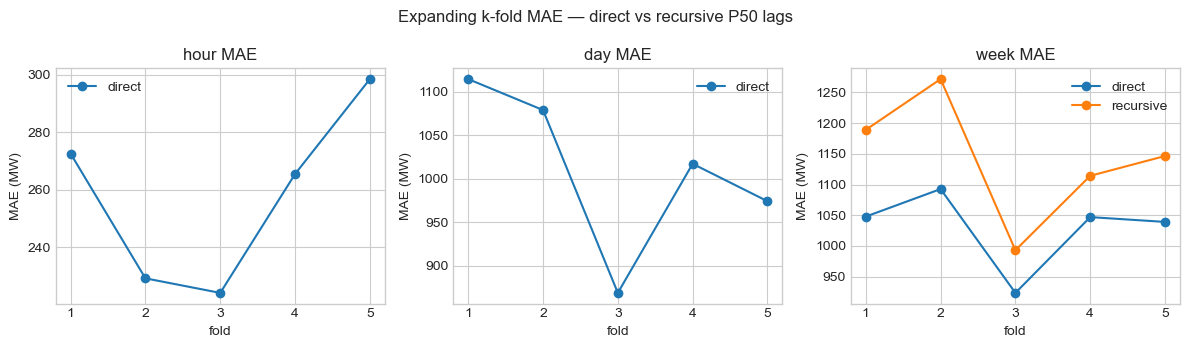

In [7]:
if folds.empty:
    print("no fold table")
else:
    plot = folds.loc[folds["split"].astype(str).str.startswith("fold")].copy()
    want = plot["pack"].map(headline_grid) == plot["grid"]
    plot = plot.loc[want] if want.any() else plot
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)
    for ax, pack in zip(axes, ["hour", "day", "week"]):
        sub = plot.loc[plot["pack"] == pack]
        if sub.empty:
            ax.set_title(pack)
            continue
        for scoring, g in sub.groupby("scoring"):
            ax.plot(g["fold"] + 1, g["mae"], marker="o", label=scoring)
        ax.set_title(f"{pack} MAE")
        ax.set_xlabel("fold")
        ax.set_ylabel("MAE (MW)")
        ax.legend()
    fig.suptitle("Expanding k-fold MAE — direct vs recursive P50 lags")
    fig.tight_layout()

## 4. Slices (pooled folds)

Season, time of day, weekday, holiday, temperature band, lead band. Mean MAE across folds.

In [8]:
slices = pd.concat(
    [t for t in (hour_slices, day_slices, week_slices) if t is not None and not t.empty],
    ignore_index=True,
)

def slice_mean(table, slice_name):
    if table.empty or "slice" not in table.columns:
        return pd.DataFrame()
    sub = table.loc[table["slice"] == slice_name]
    if sub.empty:
        return sub
    keys = [c for c in ["pack", "scoring", "split"] if c in sub.columns]
    out = (
        sub.groupby(keys, dropna=False)
        .agg(n=("n", "sum"), mae=("mae", "mean"), bias=("bias", "mean"), coverage_80=("coverage_80", "mean"))
        .reset_index()
    )
    return out.sort_values(keys)

print("season")
display(slice_mean(slices, "season"))
print("period_band")
display(slice_mean(slices, "period_band"))
print("weekday")
display(slice_mean(slices, "weekday"))
print("holiday")
display(slice_mean(slices, "holiday"))
print("temp_band")
display(slice_mean(slices, "temp_band"))
print("lead_band")
display(slice_mean(slices, "lead_band"))

season


,pack,scoring,split,n,mae,bias,coverage_80
0,day,direct,autumn,17480,962.6,155.0,0.7
1,day,direct,spring,17656,"1,011.2",-222.2,0.8
2,day,direct,summer,23334,948.5,-144.4,0.7
3,day,direct,winter,17280,"1,091.0",23.8,0.8
4,hour,direct,autumn,15714,255.8,12.0,0.8
5,hour,direct,spring,17656,254.7,-32.5,0.8
6,hour,direct,summer,16417,233.3,-37.5,0.8
7,hour,direct,winter,17328,279.6,-23.3,0.8
8,week,direct,autumn,69920,"1,115.1",51.3,0.9
9,week,direct,spring,70624,"1,191.6",-300.4,0.8


period_band


,pack,scoring,split,n,mae,bias,coverage_80
0,day,direct,afternoon,12624,"1,595.4",-273.0,0.6
1,day,direct,evening_peak,12624,"1,035.9",114.6,0.8
2,day,direct,late_evening,12628,751.2,126.8,0.8
3,day,direct,morning,18936,"1,181.4",-184.8,0.7
4,day,direct,night,18938,674.4,155.9,0.8
5,hour,direct,afternoon,11184,270.3,-20.9,0.8
6,hour,direct,evening_peak,11186,294.6,19.0,0.8
7,hour,direct,late_evening,11192,233.2,22.7,0.8
8,hour,direct,morning,16776,307.5,-78.4,0.7
9,hour,direct,night,16777,192.3,-26.2,0.8


weekday


...

,pack,scoring,split,n,mae,bias,coverage_80
0,day,direct,holiday,1536,"1,753.9","-1,086.9",0.5
1,day,direct,normal,74214,"1,014.5",4.6,0.7
2,hour,direct,holiday,1632,319.4,-108.1,0.7
3,hour,direct,normal,65483,256.2,-20.1,0.8
4,week,direct,holiday,6144,"1,824.9","-1,163.7",0.7
5,week,direct,normal,296856,"1,140.3",-43.3,0.8
6,week,recursive,holiday,6144,"2,512.6","-1,979.4",0.5
7,week,recursive,normal,296856,"1,278.4",19.5,0.8


temp_band


,pack,scoring,split,n,mae,bias,coverage_80
0,day,direct,cold,20072,917.8,57.9,0.8
1,day,direct,freezing,8566,843.3,49.2,0.7
2,day,direct,hot,6945,"1,108.2",141.8,0.7
3,day,direct,mild,23285,999.6,-55.6,0.7
4,day,direct,warm,16882,"1,077.6",-131.5,0.7
5,hour,direct,cold,20552,256.3,-21.1,0.8
6,hour,direct,freezing,11021,279.4,-26.7,0.8
7,hour,direct,hot,3932,252.5,-0.8,0.8
8,hour,direct,mild,19829,251.7,-20.9,0.8
9,hour,direct,warm,11781,245.3,-27.0,0.8


lead_band


,pack,scoring,split,n,mae,bias,coverage_80
0,week,direct,0-24h,75750,"1,071.7",-23.4,0.8
1,week,direct,24-72h,75750,"1,088.5",-51.6,0.8
2,week,direct,72-168h,151500,"1,224.8",-84.1,0.9
3,week,recursive,0-24h,75750,"1,199.0",-31.0,0.8
4,week,recursive,24-72h,75750,"1,302.8",-20.5,0.8
5,week,recursive,72-168h,151500,"1,353.9",-5.5,0.8


## 5. Direct minus recursive

Positive MAE delta: recursive is better. Week 30-min grid is the live board resolution; `medium` is the 6-hour Optuna grid.

In [9]:
if folds.empty:
    delta = pd.DataFrame()
else:
    mean = folds.loc[folds["split"] == "mean", ["pack", "scoring", "grid", "mae", "bias", "wrmsse", "n"]].copy()
    wide = mean.pivot_table(index=["pack", "grid"], columns="scoring", values=["mae", "bias", "wrmsse"])
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()
    if {"mae_direct", "mae_recursive"}.issubset(wide.columns):
        wide["mae_direct_minus_recursive"] = wide["mae_direct"] - wide["mae_recursive"]
    delta = wide
delta

,pack,grid,bias_direct,bias_recursive,mae_direct,mae_recursive,wrmsse_direct,wrmsse_recursive,mae_direct_minus_recursive
0,day,30min,-12.6,NaN,"1,027.7",NaN,0.5,NaN,NaN
1,day,short,-12.5,NaN,"1,010.9",NaN,0.5,NaN,NaN
2,hour,30min,-22.6,NaN,257.9,NaN,0.1,NaN,NaN
3,week,30min,-60.8,-15.6,"1,152.4","1,302.4",0.5,0.6,-149.9
4,week,medium,-60.0,-15.0,"1,030.1","1,142.9",0.5,0.6,-112.9


## 6. SHAP and leakage

K-fold MAE does not tell you *why* last week blew up. The week mean tree is trained on Previous Runs **history**, where `demand_lag_48` is always **real yesterday** (the outturn already exists). On a Monday freeze, Tuesday–Sunday `lag_48` is **monthly climatology**. That is train/serve skew, not a shuffled fold leaking labels.

This section uses the **saved production packs** (and last week’s frozen board rows). It does not need the k-fold cell to have finished.

- **Holdout SHAP** — what the trees rely on when lags are honest (same as training).
- **Issued last week SHAP** — what they relied on with the climatology fill.
- **True-lag counterfactual** — same weather freeze, but `lag_48` set to the actual previous day. If the guess collapses toward actual, the tree is a lag copier and weather cannot save a bad freeze.

In [ ]:
from energy_forecast.explain import explain_scored, mean_abs_shap, shap_source_share
from energy_forecast.live import WEEK, load_board, load_context_actuals
from energy_forecast.model import load_day_models, load_hour_models, load_models, predict_quantiles
from energy_forecast.regions import SERIES_ID
from energy_forecast.review import (
    _attach_frozen_and_weather,
    _ensure_calendar,
    _load_archive_weather,
    _pack_rows,
    _ready_predict_frame,
    _recompute_weather_features,
    week_review_span,
)
from energy_forecast.settlement import LONDON_TZ

SHAP_SAMPLE = 2_500
LAG_COLS = ["demand_lag_1", "demand_lag_2", "demand_lag_48", "demand_lag_336"]


def shap_ready(frame, models):
    out = _ensure_calendar(frame.copy().reset_index(drop=True))
    out["region_id"] = SERIES_ID
    work = out.drop(columns=["window_start"], errors="ignore")
    rebuilt = _recompute_weather_features(work)
    keys = ["timestamp"]
    if "lead_hours" in out.columns:
        keys = ["timestamp", "lead_hours"]
    take = [c for c in models.features if c in rebuilt.columns]
    right = rebuilt.loc[:, list(dict.fromkeys([*keys, *take]))].drop_duplicates(keys, keep="last")
    merged = out.merge(right, on=keys, how="left", suffixes=("", "_rebuilt"))
    for column in models.features:
        rebuilt_col = f"{column}_rebuilt"
        if column not in merged.columns and rebuilt_col in merged.columns:
            merged[column] = merged[rebuilt_col]
        elif rebuilt_col in merged.columns:
            merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
                pd.to_numeric(merged[rebuilt_col], errors="coerce")
            )
    merged["region_id"] = SERIES_ID
    return _ready_predict_frame(merged, models)


def sample_holdout(frame, models, n=SHAP_SAMPLE):
    need = [c for c in models.features if c in frame.columns]
    work = frame.dropna(subset=["demand_mw", *need]).copy()
    if "region_id" not in work.columns:
        work["region_id"] = SERIES_ID
    if len(work) > n:
        work = work.sample(n, random_state=0)
    return work.reset_index(drop=True)


def pack_shap(label, frame, models):
    scored = predict_quantiles(frame, models)
    shap_mean = explain_scored(scored, models)["mean"]
    rank = mean_abs_shap(shap_mean, n=12)
    share = shap_source_share(shap_mean)
    rank.insert(0, "pack", label)
    share.insert(0, "pack", label)
    return scored, shap_mean, rank, share


prod_week = load_models()
prod_day = load_day_models()
prod_hour = load_hour_models()
print("loaded hour/day/week production packs")

In [ ]:
hour_shap_in = sample_holdout(hour_holdout, prod_hour)
day_shap_in = sample_holdout(
    week_holdout.loc[pd.to_numeric(week_holdout["lead_hours"], errors="coerce").fillna(0) <= DAY_MAX_LEAD_HOURS],
    prod_day,
)
week_shap_in = sample_holdout(
    week_holdout.loc[pd.to_numeric(week_holdout["lead_hours"], errors="coerce").fillna(0) > DAY_MAX_LEAD_HOURS],
    prod_week,
)

hour_scored, hour_shap, hour_rank, hour_share = pack_shap("hour holdout", hour_shap_in, prod_hour)
day_scored, day_shap, day_rank, day_share = pack_shap("day holdout", day_shap_in, prod_day)
week_scored, week_shap, week_rank, week_share = pack_shap("week holdout", week_shap_in, prod_week)

holdout_share = pd.concat([hour_share, day_share, week_share], ignore_index=True)
print("Holdout mean |SHAP| share — honest lags (same regime as training)")
display(holdout_share.pivot(index="source", columns="pack", values="share"))
print("Week holdout top features")
display(week_rank)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, rank, title in (
    (axes[0], hour_rank, "Hour holdout"),
    (axes[1], day_rank, "Day holdout"),
    (axes[2], week_rank, "Week holdout"),
):
    ax.barh(rank["feature"].iloc[::-1], rank["mean_abs_shap"].iloc[::-1])
    ax.set_title(title)
    ax.set_xlabel("mean |SHAP| (MW)")
fig.suptitle("Production mean trees — holdout (true lags)")
fig.tight_layout()

In [ ]:
start, end = week_review_span(load_board(), load_context_actuals())
board = load_board()
ctx = load_context_actuals()
joined = _attach_frozen_and_weather(
    WEEK,
    _pack_rows(WEEK, board, ctx).dropna(subset=["actual_mw", "p50"]),
    _load_archive_weather(),
)
joined["timestamp"] = pd.to_datetime(joined["timestamp"], utc=True)
start_u, end_u = pd.to_datetime(start, utc=True), pd.to_datetime(end, utc=True)
live_week = joined.loc[(joined["timestamp"] >= start_u) & (joined["timestamp"] < end_u)].copy()
live_week = live_week.reset_index(drop=True)
live_week["region_id"] = SERIES_ID
print("live week", pd.Timestamp(start).tz_convert(LONDON_TZ), "->", pd.Timestamp(end).tz_convert(LONDON_TZ), "n", len(live_week))

issued_in = shap_ready(live_week, prod_week)
issued_hat = predict_quantiles(issued_in, prod_week)
issued_shap = explain_scored(issued_hat, prod_week)["mean"]
issued_rank = mean_abs_shap(issued_shap, n=12)
issued_share = shap_source_share(issued_shap)
issued_share.insert(0, "pack", "week issued freeze")
issued_rank.insert(0, "pack", "week issued freeze")

true_in = issued_in.copy()
actual_by_ts = (
    pd.to_numeric(live_week["actual_mw"], errors="coerce")
    .groupby(pd.to_datetime(live_week["timestamp"], utc=True))
    .mean()
)
ts = pd.to_datetime(true_in["timestamp"], utc=True)
true_in["demand_lag_48"] = (ts - pd.Timedelta(days=1)).map(actual_by_ts).combine_first(
    pd.to_numeric(true_in["demand_lag_48"], errors="coerce")
)
true_hat = predict_quantiles(true_in, prod_week)
true_shap = explain_scored(true_hat, prod_week)["mean"]
true_rank = mean_abs_shap(true_shap, n=12)
true_share = shap_source_share(true_shap)
true_share.insert(0, "pack", "week true lag_48")
true_rank.insert(0, "pack", "week true lag_48")

live_cmp = pd.DataFrame(
    {
        "model": ["issued (climatology lag_48)", "true yesterday lag_48"],
        "mae": [
            float((pd.to_numeric(live_week["actual_mw"], errors="coerce") - issued_hat["p50"]).abs().mean()),
            float((pd.to_numeric(live_week["actual_mw"], errors="coerce") - true_hat["p50"]).abs().mean()),
        ],
        "mean_p50": [float(issued_hat["p50"].mean()), float(true_hat["p50"].mean())],
        "mean_actual": [float(pd.to_numeric(live_week["actual_mw"], errors="coerce").mean())] * 2,
        "mean_lag_48": [float(issued_in["demand_lag_48"].mean()), float(true_in["demand_lag_48"].mean())],
    }
)
print("Same trees, same weather freeze; only lag_48 changes")
display(live_cmp)
print("SHAP source share")
display(pd.concat([issued_share, true_share], ignore_index=True).pivot(index="source", columns="pack", values="share"))
print("Issued freeze top |SHAP|")
display(issued_rank)

In [ ]:
local = pd.to_datetime(issued_hat["timestamp"], utc=True).dt.tz_convert(LONDON_TZ)
nnoon = (local.dt.hour == 12) & (local.dt.minute == 0)
picks = issued_hat.loc[nnoon, ["timestamp", "p50"]].copy()
picks["actual"] = pd.to_numeric(live_week.loc[nnoon, "actual_mw"], errors="coerce").to_numpy()
picks["lag_48_issued"] = pd.to_numeric(issued_in.loc[nnoon, "demand_lag_48"], errors="coerce").to_numpy()
picks["lag_48_true"] = pd.to_numeric(true_in.loc[nnoon, "demand_lag_48"], errors="coerce").to_numpy()
picks["p50_true_lag"] = pd.to_numeric(true_hat.loc[nnoon, "p50"], errors="coerce").to_numpy()
picks["day"] = local.loc[nnoon].dt.strftime("%a %d %b")


def top_shap(idx, shap_frame, n=6):
    row = shap_frame.loc[idx].drop(labels=["shap_base"], errors="ignore")
    top = row.abs().sort_values(ascending=False).head(n)
    return pd.DataFrame({"feature": top.index, "shap_mw": row.reindex(top.index).to_numpy()})


print("Lunch 12:00 — issued vs true lag_48")
display(picks.loc[:, ["day", "actual", "p50", "p50_true_lag", "lag_48_issued", "lag_48_true"]].reset_index(drop=True))

for _, r in picks.iterrows():
    idx = r.name
    day = r["day"]
    print(f"\n{day} 12:00 issued SHAP (what the freeze used)")
    display(top_shap(idx, issued_shap))
    print(f"{day} 12:00 true-lag SHAP")
    display(top_shap(idx, true_shap))

In [ ]:
def corr_lag(frame, lag="demand_lag_48", y="demand_mw"):
    a = pd.to_numeric(frame[lag], errors="coerce")
    b = pd.to_numeric(frame[y], errors="coerce")
    return float(a.corr(b))

week_lag_holdout = corr_lag(week_shap_in)
hour_lag_holdout = corr_lag(hour_shap_in, "demand_lag_1") if "demand_lag_1" in hour_shap_in.columns else float("nan")
live_y = pd.to_numeric(live_week["actual_mw"], errors="coerce")
live_lag_issued = float(pd.to_numeric(issued_in["demand_lag_48"], errors="coerce").corr(live_y))
live_lag_true = float(pd.to_numeric(true_in["demand_lag_48"], errors="coerce").corr(live_y))

week_share_lag = float(week_share.loc[week_share["source"] == "demand_lag", "share"].sum())
issued_share_lag = float(issued_share.loc[issued_share["source"] == "demand_lag", "share"].sum())

leak = pd.DataFrame(
    [
        {
            "check": "Week tree |SHAP| from demand lags on holdout",
            "value": week_share_lag,
            "note": "High means the tree copies yesterday. Expected in train. Dangerous on a Monday freeze.",
        },
        {
            "check": "corr(lag_48, actual) on week holdout",
            "value": week_lag_holdout,
            "note": "High is not CV leakage — yesterday really predicts today. It is why climatology fill hurts.",
        },
        {
            "check": "corr(lag_1, actual) on hour holdout",
            "value": hour_lag_holdout,
            "note": "Hour pack is supposed to use the last INDO print. Live next-30 has that number.",
        },
        {
            "check": "corr(issued lag_48, actual) last live week",
            "value": live_lag_issued,
            "note": "Drops vs holdout if freeze filled climatology instead of yesterday.",
        },
        {
            "check": "corr(true lag_48, actual) last live week",
            "value": live_lag_true,
            "note": "Should look like holdout. Gap vs issued corr is the freeze gap.",
        },
        {
            "check": "Week |SHAP| from demand lags on issued freeze",
            "value": issued_share_lag,
            "note": "If this stays high while issued lag_48 is climatology, the tree still trusts the fake lag.",
        },
        {
            "check": "K-fold embargo_days",
            "value": float(EMBARGO_DAYS),
            "note": "0 = last week of train can be lag_336 for test. That matches live. 7 would drop that overlap.",
        },
    ]
)
print("Leakage / skew checklist")
display(leak)
print(
    "If holdout lag share is high and issued last-week MAE falls a lot with true lag_48, "
    "last week was not a leaky k-fold. The live freeze fed the tree a lag it never saw in training."
)